# BS49903 · DS/AI for Biology
## Assignment 2 - SOLUTIONS

**Due: Friday, November 13, 11:59 PM**

**Instructions.** Work through the exercises in order. Fill in every cell marked `#### YOUR CODE HERE ####` and answer the written questions in the markdown cells provided. You may use any publicly available Python package unless instructed otherwise. Do not delete the cells that are given to you.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

%matplotlib inline

-----
## Part 1 — PCA and k-means on the Breast Cancer Wisconsin dataset

The Breast Cancer Wisconsin dataset contains **569 biopsies**. For each biopsy, **30 features** were measured from the cell nuclei in a digitised image (mean radius, mean texture, mean concavity, …). Each biopsy is labelled **malignant** (0) or **benign** (1).

In this part you will implement the two unsupervised methods from the lectures — **PCA** and **k-means** — *from scratch* with NumPy, and check your implementations against `scikit-learn`. The labels are only used at the very end, to see whether the structure we find without them is biologically meaningful.

Run the cell below to load the data.

In [2]:
data = load_breast_cancer()
X_raw = data.data          # shape (569, 30)
y = data.target            # 0 = malignant, 1 = benign
feature_names = data.feature_names

print("X_raw shape:", X_raw.shape)
print("Number of malignant / benign:", (y == 0).sum(), "/", (y == 1).sum())
pd.DataFrame(X_raw, columns=feature_names).head()

X_raw shape: (569, 30)
Number of malignant / benign: 212 / 357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Exercise 1.1 (1 pt)

Features in this dataset live on wildly different scales (`mean area` is in the hundreds, `mean fractal dimension` is around 0.06). PCA finds the directions of largest **variance**, so without rescaling the first component would simply point along `mean area`.

**Standardize** every feature so that it has mean 0 and standard deviation 1 across the 569 samples:

$$
x_{ij}^{\text{scaled}} = \frac{x_{ij} - \mu_j}{\sigma_j}
$$

**Implement this yourself with NumPy** (do not use `StandardScaler` to compute `X`), store the result in `X`, and then verify your result against `StandardScaler().fit_transform(X_raw)` by printing the maximum absolute difference between the two.

In [3]:
mu = X_raw.mean(axis=0)
sigma = X_raw.std(axis=0)        # ddof=0, same as StandardScaler
X = (X_raw - mu) / sigma         # shape (569, 30), each column with mean 0 and std 1

X_sklearn = StandardScaler().fit_transform(X_raw)
print("Column means (first 5):", X.mean(axis=0)[:5].round(6))
print("Column stds  (first 5):", X.std(axis=0)[:5].round(6))
print("max |difference| vs StandardScaler:", np.abs(X - X_sklearn).max())

Column means (first 5): [-0. -0. -0. -0.  0.]
Column stds  (first 5): [1. 1. 1. 1. 1.]
max |difference| vs StandardScaler: 0.0


### Exercise 1.2 (2.5 pts)

PCA can be computed directly from the **singular value decomposition** of the centred data matrix. Our `X` is already centred (every column has mean 0), so

$$
X = U \, S \, V^\top
$$

where the columns of $V$ are the **principal directions** (the loadings), and the singular values $s_1 \ge s_2 \ge \dots$ on the diagonal of $S$ tell us how much variance each direction carries:

$$
\text{variance along PC}_k = \frac{s_k^2}{n-1}, \qquad
\text{explained variance ratio}_k = \frac{s_k^2}{\sum_j s_j^2}
$$

The **scores** (the coordinates of every sample in the new axes) are the projection of the data onto the principal directions:

$$
Z = X V \;=\; U S
$$

NumPy computes the SVD with

```python
U, s, Vt = np.linalg.svd(X, full_matrices=False)   # s is a 1-D array of singular values, Vt = V^T
```

**Implement this yourself with NumPy** — do not use `sklearn.decomposition.PCA` in this exercise.

1. Compute the SVD of `X` with `np.linalg.svd`.
2. **Calculate the explained variance ratio yourself** from the singular values `s`, using the formula above, for **all 30** components and store it in `evr_svd`.
3. **Calculate the scores yourself** on the **first two** components, store them in `Z_svd` (shape `(569, 2)`), and store the corresponding two principal directions in `W_svd` (shape `(2, 30)`, one row per component).
4. Print the explained variance ratio of PC1 and PC2, and run the plotting code that follows.

Explained variance ratio, PC1 and PC2: [0.4427 0.1897]
Cumulative explained variance, first 10 PCs: [0.443 0.632 0.726 0.792 0.847 0.888 0.91  0.926 0.94  0.952]


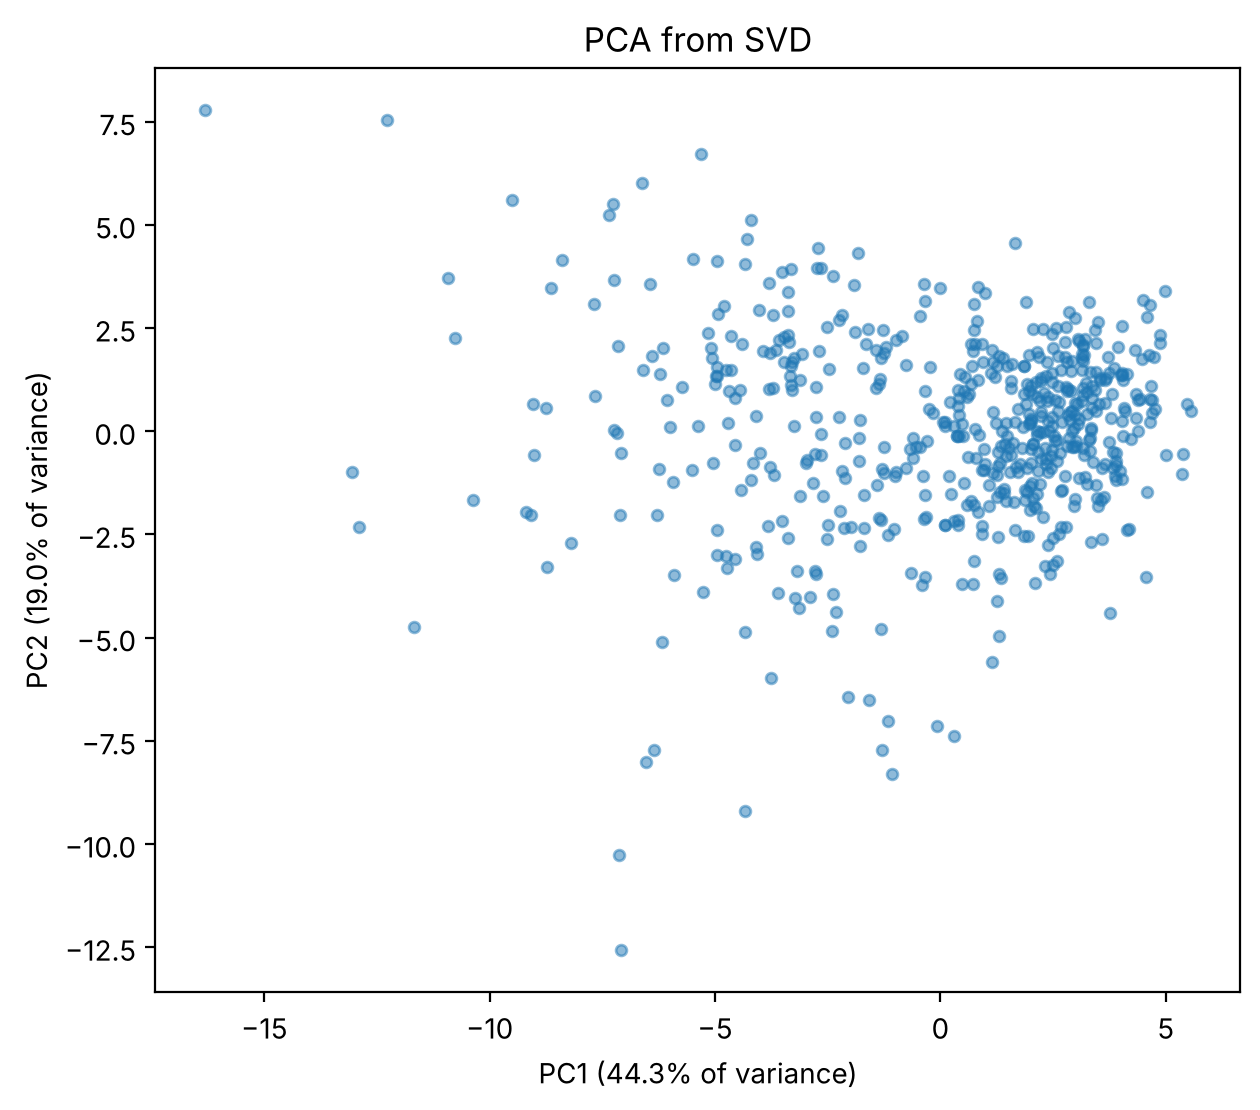

In [4]:
U, s, Vt = np.linalg.svd(X, full_matrices=False)

evr_svd = s**2 / np.sum(s**2)   # shape (30,), sums to 1
W_svd = Vt[:2]                   # shape (2, 30): first two principal directions
Z_svd = X @ Vt[:2].T             # shape (569, 2): scores on PC1 and PC2 (equivalently U[:, :2] * s[:2])

print("Explained variance ratio, PC1 and PC2:", evr_svd[:2].round(4))
print("Cumulative explained variance, first 10 PCs:", np.cumsum(evr_svd)[:10].round(3))

# plot the samples in the PC1 / PC2 plane
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(Z_svd[:, 0], Z_svd[:, 1], alpha=0.5, s=15)
ax.set_xlabel(f"PC1 ({100 * evr_svd[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * evr_svd[1]:.1f}% of variance)")
ax.set_title("PCA from SVD")
plt.show()

### Exercise 1.3 (2 pts)

Now compare your result with `scikit-learn`:

```python
pca = PCA(n_components=2)
Z_sk = pca.fit_transform(X)
pca.components_                # shape (2, 30)
pca.explained_variance_ratio_  # shape (2,)
```

1. Fit `PCA(n_components=2)` on `X` and print its explained variance ratio next to yours.
2. Compare `pca.components_` with your `W_svd`, and `Z_sk` with your `Z_svd`, by printing the maximum absolute difference **for each component separately**.
3. In the markdown cell, explain what you observe. If a component does not match, is your implementation wrong? (*Hint: a principal direction $v$ and its negative $-v$ describe exactly the same axis.*)

In [5]:
pca = PCA(n_components=2)
Z_sk = pca.fit_transform(X)

print("Explained variance ratio  scikit-learn:", pca.explained_variance_ratio_.round(4))
print("Explained variance ratio  SVD:         ", evr_svd[:2].round(4))

for k in range(2):
    diff_W = np.abs(pca.components_[k] - W_svd[k]).max()   # max |difference| between the k-th principal direction
    diff_Z = np.abs(Z_sk[:, k] - Z_svd[:, k]).max()         # max |difference| between the k-th score column
    print(f"PC{k+1}:  max |diff| directions = {diff_W:.2e}   max |diff| scores = {diff_Z:.2e}")

# allowing for a sign flip, both components agree to round-off
for k in range(2):
    sign = np.sign(pca.components_[k] @ W_svd[k])
    diff_W = np.abs(pca.components_[k] - sign * W_svd[k]).max()
    diff_Z = np.abs(Z_sk[:, k] - sign * Z_svd[:, k]).max()
    print(f"PC{k+1} (sign-corrected, sign = {sign:+.0f}):  directions {diff_W:.2e}   scores {diff_Z:.2e}")

Explained variance ratio  scikit-learn: [0.4427 0.1897]
Explained variance ratio  SVD:          [0.4427 0.1897]
PC1:  max |diff| directions = 5.22e-01   max |diff| scores = 3.26e+01
PC2:  max |diff| directions = 7.33e-01   max |diff| scores = 2.51e+01
PC1 (sign-corrected, sign = -1):  directions 2.50e-16   scores 7.11e-15
PC2 (sign-corrected, sign = -1):  directions 2.50e-16   scores 8.88e-15


**Solution.** The explained variance ratios are identical (PC1 ≈ 0.443, PC2 ≈ 0.190, matching the lecture). The principal directions and scores agree up to round-off ($\sim10^{-14}$) **or** differ by exactly a factor of $-1$: on most machines one or both components come out with the opposite sign, so the max difference is about twice the largest entry rather than $\sim10^{-14}$. This is **not** an error. A principal direction is an axis, and $v$ and $-v$ span the same axis and carry the same variance; the SVD is only unique up to the sign of each $(u_k, v_k)$ pair, and `scikit-learn` applies its own sign convention (`svd_flip`) to make its output deterministic. Flipping the sign of a direction flips the sign of the corresponding score column, so after sign-correcting the differences are $\sim10^{-14}$ for both components (second block of output).

*Grading note:* full credit for recognising the sign ambiguity; an answer that concludes "my implementation is wrong" because of a sign flip loses points.

### Exercise 1.4 (3 pts)

Now **implement k-means yourself, from scratch with NumPy** — do not use `sklearn.cluster.KMeans` in this exercise. Recall the algorithm from the lecture:

1. **Initialize** $k$ centroids. Here, pick $k$ samples at random from the data (using `rng` so your result is reproducible).
2. **Assign** every sample to its nearest centroid (Euclidean distance over all 30 features).
3. **Update** each centroid to the mean of the samples assigned to it.
4. Repeat 2–3 until the assignments stop changing (or `max_iter` is reached).

The objective that k-means minimises is the **within-cluster sum of squares** (also called *inertia*):

$$
J = \sum_{i=1}^{n} \lVert x_i - c_{a(i)} \rVert^2
$$

where $a(i)$ is the cluster assigned to sample $i$ and $c_j$ is the centroid of cluster $j$.

Fill in the function `kmeans` below: **write the assignment step, the centroid update and the inertia $J$ yourself**. It must return the final labels (an integer array of length $n$), the final centroids (shape `(k, p)`), and the final value of $J$. Then run it on `X` with $k = 2$ and print $J$ and the number of samples in each cluster.

In [6]:
rng = np.random.default_rng(seed=0)


def kmeans(X, k, rng, max_iter=100):
    """k-means clustering from scratch.

    Returns
    -------
    labels    : int array of shape (n,)   cluster id of every sample
    centroids : array of shape (k, p)     final centroid of every cluster
    inertia   : float                     within-cluster sum of squares J
    """
    n, p = X.shape

    # 1. initialize: pick k distinct samples as the starting centroids
    init_idx = rng.choice(n, size=k, replace=False)
    centroids = X[init_idx].copy()

    labels = np.full(n, -1)
    for it in range(max_iter):
        # 2. assign every sample to the nearest centroid
        d2 = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)   # (n, k) squared distances
        new_labels = d2.argmin(axis=1)

        # stop if nothing changed
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels

        # 3. move every centroid to the mean of its samples
        for j in range(k):
            if np.any(labels == j):            # guard against an empty cluster
                centroids[j] = X[labels == j].mean(axis=0)

    d2 = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    inertia = d2[np.arange(n), labels].sum()
    return labels, centroids, inertia


labels_mine, centroids_mine, J_mine = kmeans(X, k=2, rng=rng)

print("J (inertia):", round(J_mine, 2))
print("Cluster sizes:", np.bincount(labels_mine))

J (inertia): 11595.68
Cluster sizes: [188 381]


### Exercise 1.5 (1.5 pts)

There is nothing to implement here. Run the cell below to check your k-means against `scikit-learn`'s `KMeans`. Your inertia should be very close to `scikit-learn`'s, and the agreement between the two should be close to 1 (small differences can come from the different starting centroids); if not, revisit Exercise 1.4. The plot shows the samples in the PC1/PC2 plane from Exercise 1.2, coloured by your clusters (left) and by the true malignant/benign labels (right).

**Question:** In the markdown cell below, answer: where in the PC1/PC2 plane do the k-means clusters disagree with the true labels, and why might that be?

Inertia  from scratch: 11595.68
Inertia  scikit-learn: 11595.53
Agreement, from scratch vs scikit-learn: 0.9895
Agreement, from scratch vs true labels:  0.9121


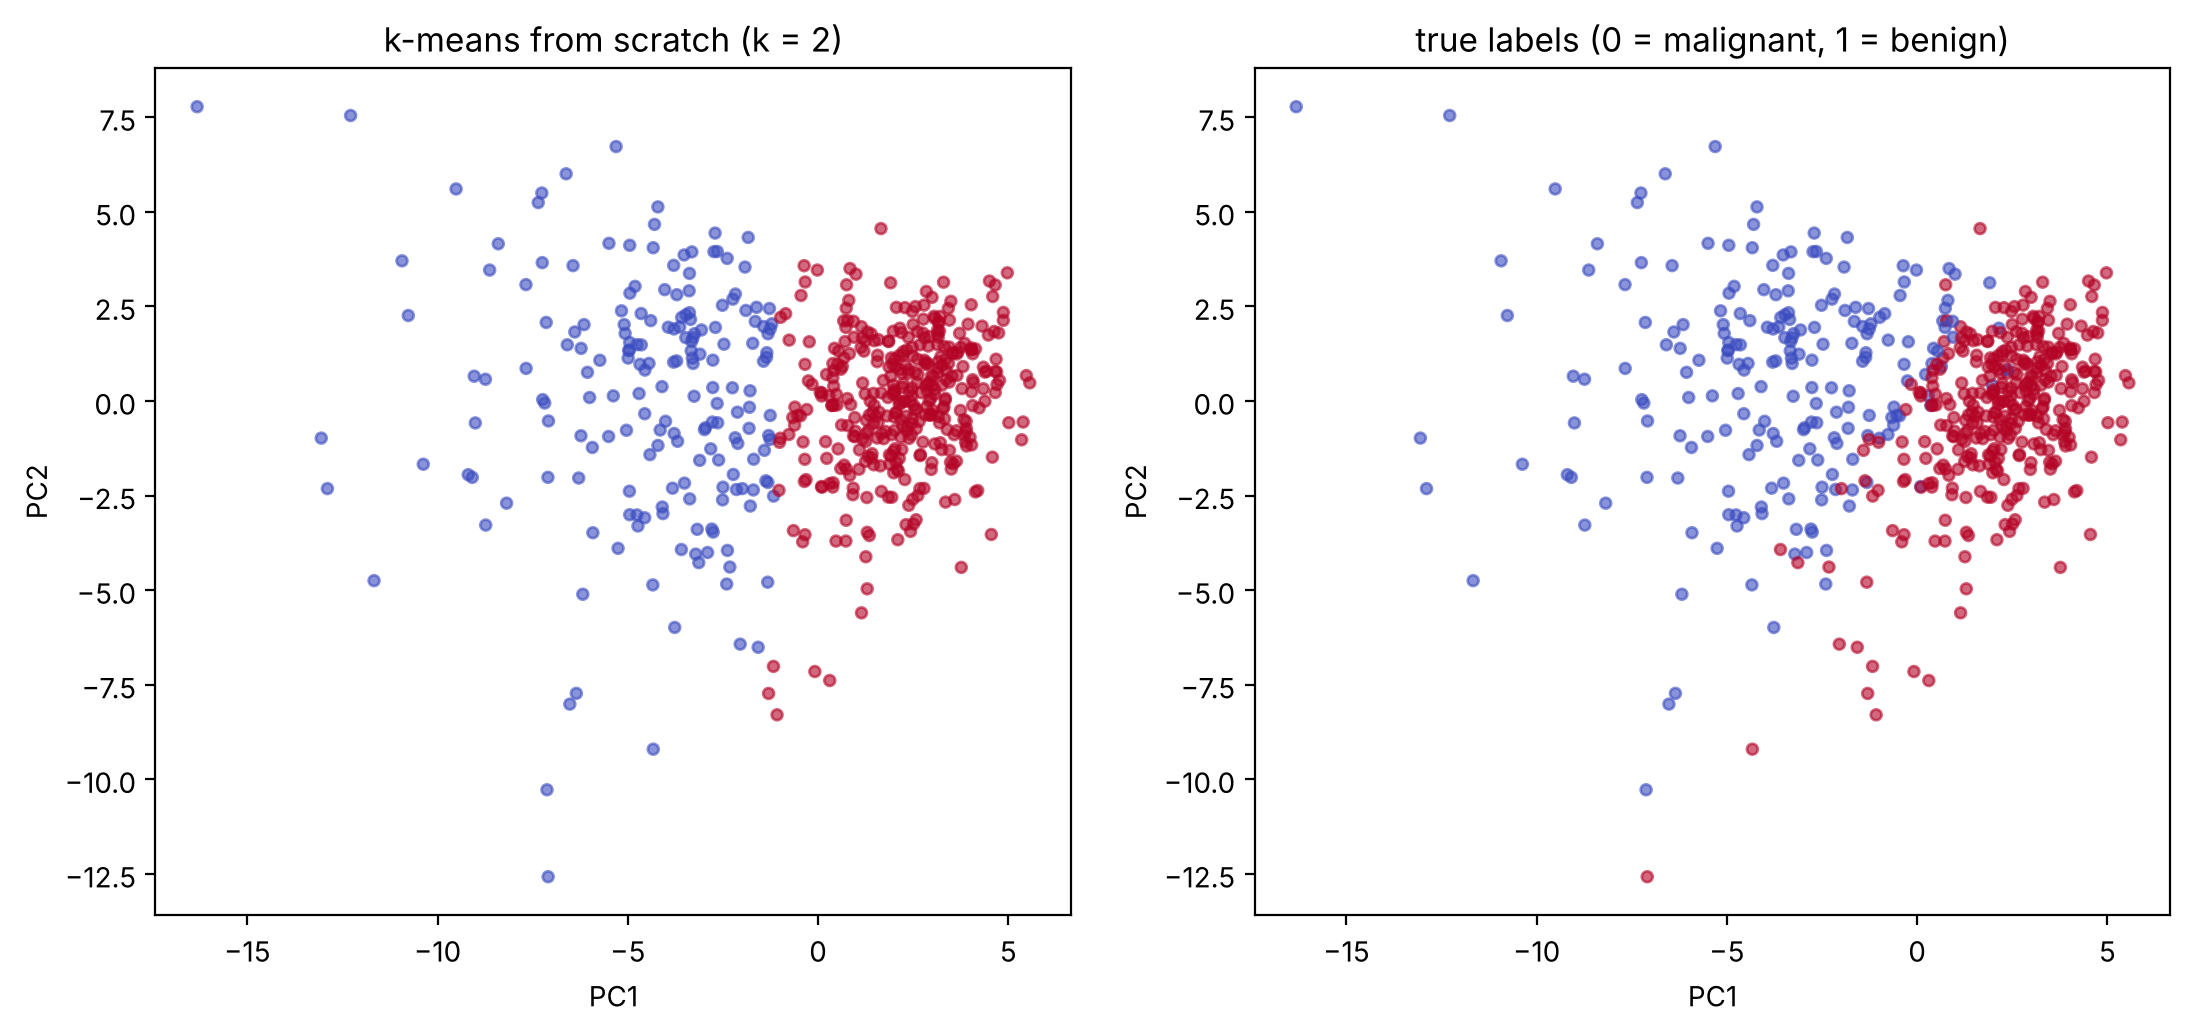

In [7]:
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)

print(f"Inertia  from scratch: {J_mine:.2f}")
print(f"Inertia  scikit-learn: {km.inertia_:.2f}")

# cluster ids are arbitrary (your 0 may be scikit-learn's 1), so take the better of the two matchings
def agreement(a, b):
    same = np.mean(a == b)
    return max(same, 1 - same)

print(f"Agreement, from scratch vs scikit-learn: {agreement(labels_mine, km.labels_):.4f}")
print(f"Agreement, from scratch vs true labels:  {agreement(labels_mine, y):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, colour, title in [(axes[0], labels_mine, "k-means from scratch (k = 2)"),
                          (axes[1], y, "true labels (0 = malignant, 1 = benign)")]:
    ax.scatter(Z_svd[:, 0], Z_svd[:, 1], c=colour, cmap="coolwarm", alpha=0.6, s=15)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(title)
plt.show()

**Solution.** 

**Where the disagreements are.** k-means, which never saw the labels, recovers the malignant/benign split for about 91% of the samples, because the largest source of variance in the standardised features (PC1, 44%) is essentially nucleus size and irregularity, and that is also what separates malignant from benign. The mismatches sit along the boundary between the two clouds, roughly at $\text{PC1} \approx 0$: these are mostly malignant samples with small or regular-looking nuclei that land on the benign side.

**Why.** The two clusters have **different spread** and are **not clearly separated**. k-means assigns each sample to the nearest centroid, so its boundary is the straight line halfway between the two centroids, and it implicitly assumes two round clusters of similar size. The malignant cloud is much more spread out along PC1 than the benign one, and the two clouds overlap near $\text{PC1} \approx 0$, so the midpoint boundary cuts into the malignant tail and hands those borderline samples to the benign cluster.